In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from glob import glob

In [142]:
!ls /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I*/vamb_multi/umap_vamb.tsv

/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I01_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I01_3/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I02_2/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I02_3/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I02_4/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I03_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I11_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I12_1/vamb_multi/umap_vamb.tsv


In [183]:
sample = "I11_2"

binning_dir = f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir"
taxo_dir = f"/gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir"

In [184]:
df_umap_coords = pd.read_csv(f"{binning_dir}/{sample}/vamb_multi/umap_vamb.tsv", sep = '\t')
df_umap_coords['sample'] = df_umap_coords.contig_id.apply(lambda x: x.split('_')[0])
df_umap_coords.head()

,contig_id,umap_0,umap_1,sample
0,3300074488_Ga0614537_0000291,10.707815,13.231590,3300074488
1,3300074488_Ga0614537_0000686,2.536328,10.013812,3300074488
2,3300074488_Ga0614537_0000916,11.434349,13.387524,3300074488
3,3300074488_Ga0614537_0001005,9.632932,13.721127,3300074488
4,3300074488_Ga0614537_0001125,5.323943,7.552617,3300074488


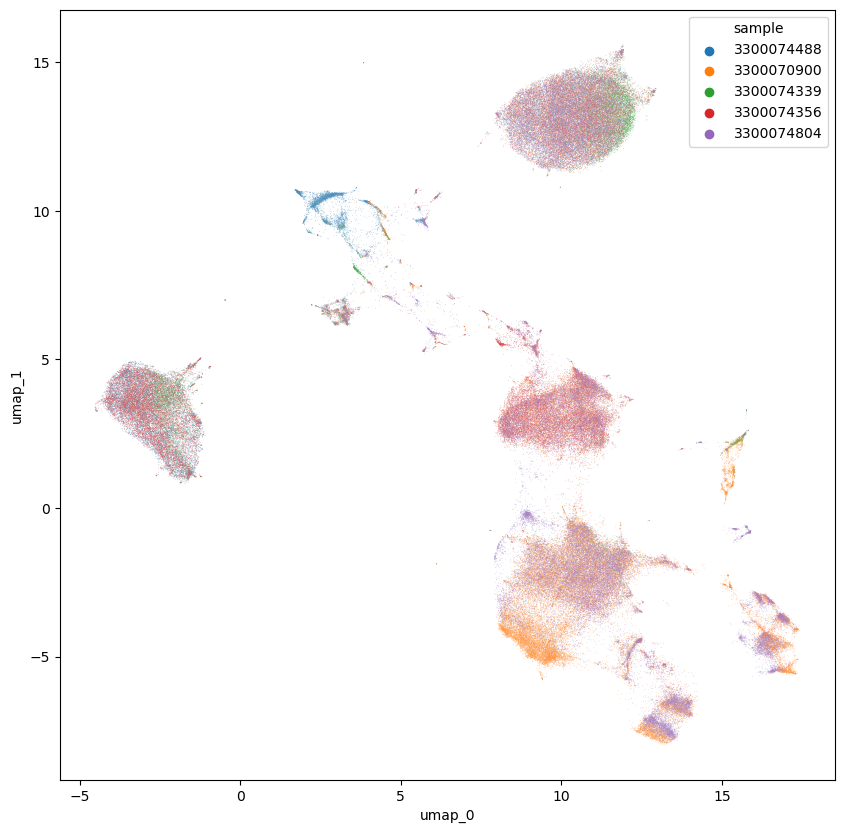

In [185]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df_umap_coords, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'sample',
    alpha = 0.5
)

In [186]:
single_samples = list(set(df_umap_coords['sample']))

def make_taxo_df(sample_id):
    df = pd.read_csv(f"{taxo_dir}/{sample_id}/{sample_id}.faa.mms2lca", sep = '\t')
    df['sample'] = sample_id
    df['contig_id'] = df['sample'] + '_' + df['contig_id']
    return df

df_taxo = pd.concat(
    make_taxo_df(s) for s in single_samples
)

df = pd.merge(
    df_umap_coords, 
    df_taxo, 
    on = ['contig_id', 'sample'],
    how = 'left'
).fillna("Unknown")

In [187]:
#top_10 = list(df.groupby('name').count().sort_values('contig_id', ascending = False).head(10).index)

favourite_groups = [
    "Bacillariophyta", 
    "Nucleocytoviricota", 
    "Mamiellophyceae",
    "Dinophyceae",
    "Metazoa",
    "Cryptophyceae",
    "Haptophyta", 
    "Chlorophyta", 
    "Euglenozoa",
    "Ciliophora",
    "Labyrinthulomycetes", 
    "Chrysophyceae", 
    "Choanoflagellata", 
    "Microbotryomycetes", 
    "Amoebozoa", 
    "Ochrophyta", 
    "Chytridiomycota"
]


def simplify_name(row):
    if row.superkingdom in ["Bacteria", "Archaea"]:
        return "Prokaryota"
    
    if row.superkingdom == "Unknown":
        if row['name'] == "Viruses":
            return "Viruses"
        return "Unknown"
    
    for x in favourite_groups:
        if x in row.lineage:
            return x

    if row.superkingdom == "Virus":
        return "Viruses"
    
    return row.superkingdom
    
    
df['name_simple'] = df.apply(simplify_name, axis = 1)

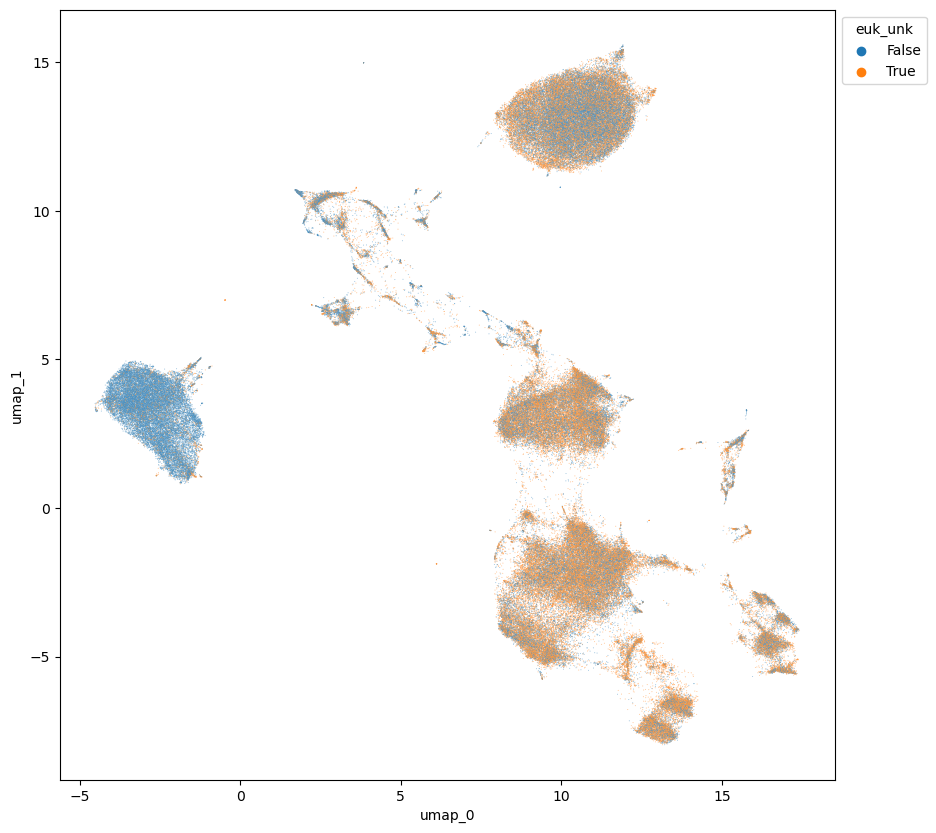

In [188]:
df['euk_unk'] = df.name_simple.isin(["Unknown", "Eukaryota"])

plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df,
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.5, 
    hue = 'euk_unk',
    alpha = 0.5
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

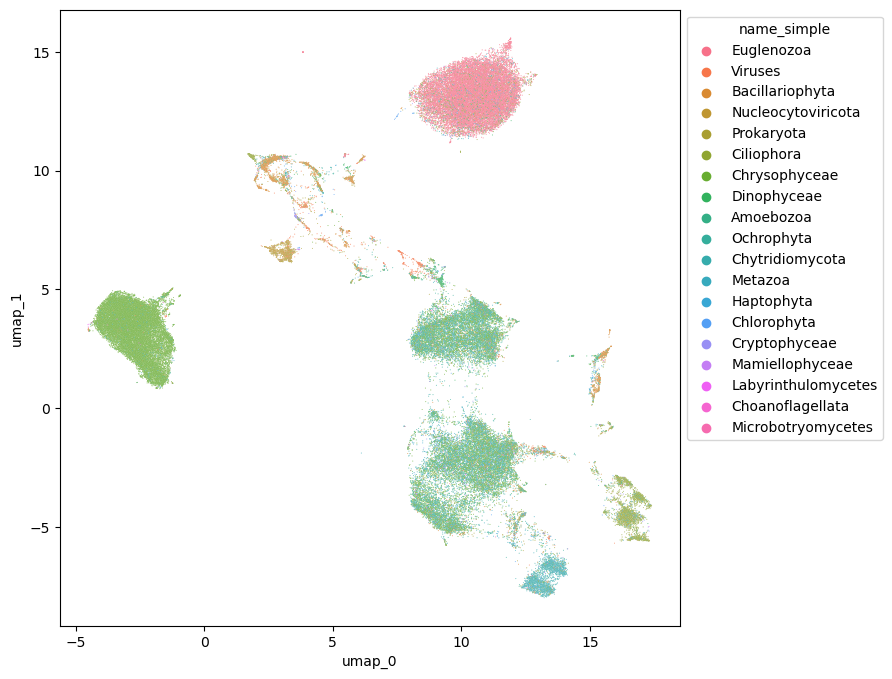

In [189]:
plt.figure(figsize = (8, 8))
ax = sns.scatterplot(
    data = df[~df.name_simple.isin(["Unknown", "Eukaryota"])],
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.5, 
    hue = 'name_simple',
    alpha = 0.85
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [190]:
#Below here is done on a per-sample basis... Don't rerun!


In [191]:
df[
    df.euk_unk & (df.umap_0 <-4 ) &(df.umap_1 > 10)
].groupby('lineage').count().sort_values('contig_id', ascending = False).head(20)

,contig_id,umap_0,umap_1,sample,taxid,superkingdom,taxon,name,name_simple,euk_unk
lineage,,,,,,,,,,


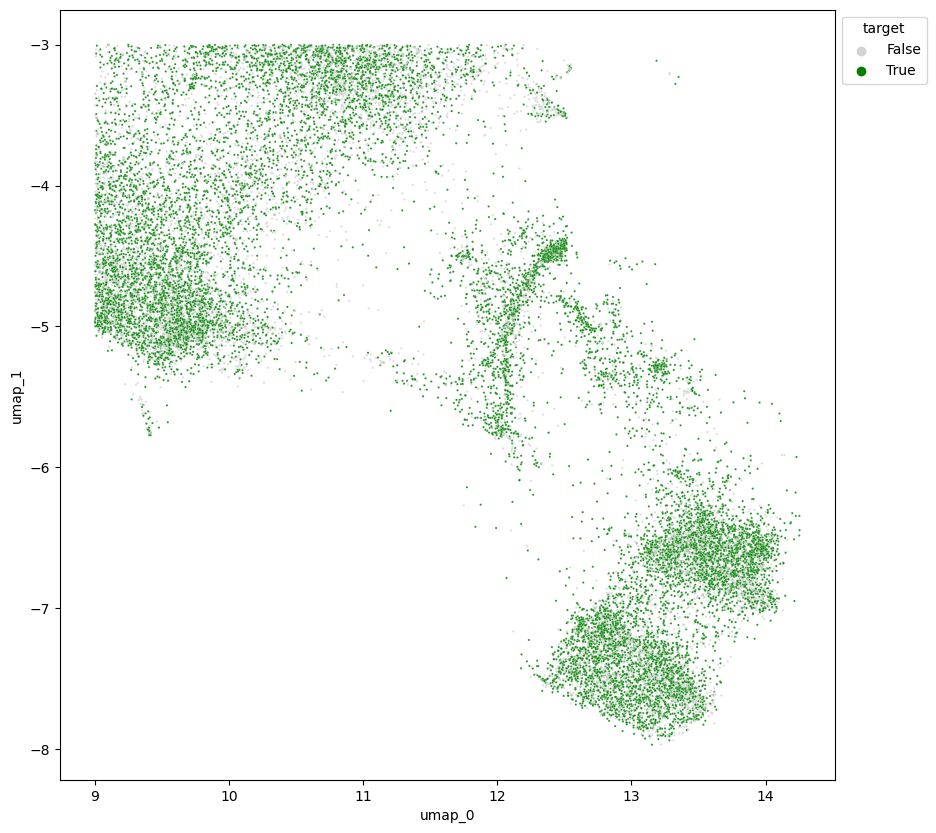

In [192]:
df['target'] = ((df.umap_0 > 9) & (df.umap_0 < 15) & (df.umap_1 > -10) & (df.umap_1 < -3)
    & df.name_simple.isin(["Eukaryota", "Unknown", "Mamiellophyceae"]) 
)

plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df[(df.umap_0 > 9) & (df.umap_0 < 15) & (df.umap_1 > -10) & (df.umap_1 < -3)],
    x = 'umap_0', 
    y = 'umap_1', 
    s = 2.5, 
    hue = 'target', palette = ['lightgrey', 'green'],
    alpha = 0.85
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [193]:
#df[(df.umap_0 > 9) & (df.umap_0 < 15) & (df.umap_1 > -10) & (df.umap_1 < -3) & df.target].groupby(
#    'lineage'
#).count().sort_values('contig_id', ascending = False).head(25)

In [194]:
#pathname = "/gpfs/home/qcf21tku/scratch/mosaic_euks_test_tmp/E06_1_mamiellophyceae_2_v1"
#df[df.target][['contig_id']].to_csv(
#    f"{pathname}.contigs.txt",
#    index = False, header = False
#)

In [195]:
#! mkdir -p {pathname}_checked

In [196]:
#! seqkit grep -f {pathname}.contigs.txt -o {pathname}.a.fna {binning_dir}/{sample}/{sample}.euks.fna

In [197]:
#! cat {pathname}.contigs.txt | cut -f 1 -d '_' | sort | uniq -c